In [36]:
import yfinance as yf
import pandas as pd 
import numpy as np
import matplotlib as mpl
import sklearn as sklearn
import matplotlib.pyplot as plt


In [ ]:
print('ok', len(yf.Ticker('AAPL').history(period='5d')), 'days pulled')


ok 5 days pulled


In [ ]:
ticker = "SANM" #Sanmina Corp.
data = yf.download(ticker)

[*********************100%***********************]  1 of 1 completed


In [43]:
#Pull one year of data for SANM and SPY. # Question 6
data = yf.download([ticker, "SPY"], period = '1y')["Close"]
#Drop empty rows
data = data.dropna()

#See results:
print("Tickers:", ticker +","+ "SPY")
print("Number of trading days:", len(data))
print("First date:", data.index[0])
print("Last date:", data.index[-1])



[*********************100%***********************]  2 of 2 completed

Tickers: SANM,SPY
Number of trading days: 251
First date: 2025-09-19 00:00:00
Last date: 2026-09-18 00:00:00


In [ ]:
#Question 7
print("SANM last close:",data["SANM"].iloc[-1])
print("SPY last close:",data["SPY"].iloc[-1])

#Return over year
#(end price - beginning price)/ beginning price
sanm_return = ((data["SANM"].iloc[-1]-data["SANM"].iloc[0])/data["SANM"].iloc[0])
spy_return = ((data["SPY"].iloc[-1]-data["SPY"].iloc[0])/data["SPY"].iloc[0])

print("Sanmina Corporation return: ", sanm_return*100,"%")
print("SPY return: ", spy_return*100,"%")

#Annualized Volatility
#Calculate Daily returns
sanm_daily_returns = data["SANM"].pct_change()
spy_daily_returns = data["SPY"].pct_change()
#Get standard dev.
sanm_volatility = (sanm_daily_returns.std() * np.sqrt(252))*100
spy_volatility = (spy_daily_returns.std() * np.sqrt(252))*100

print("Sanmina Corporation Volatility: ", sanm_volatility,"%")
print("SPY Volatility: ", spy_volatility,"%")







SANM last close: 199.55999755859375
SPY last close: 761.6900024414062
Sanmina Corporation return:  68.68976535130233 %
SPY return:  16.0023576881791 %
Sanmina Corporation Volatility:  72.56532631615097 %
SPY Volatility:  12.926146831645028 %


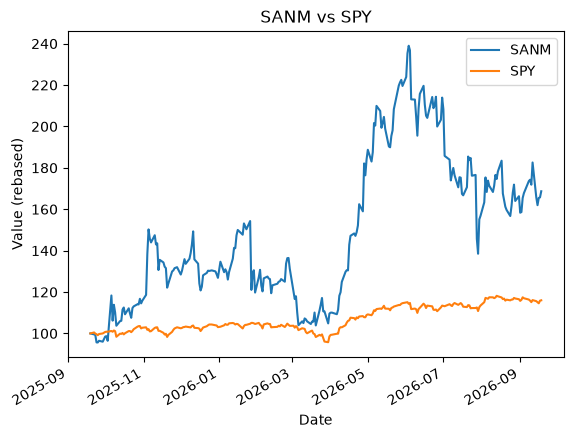

In [37]:
#Question 8
#Rebase both stocks to 100
rebased_stocks = data / data.iloc[0] * 100

rebased_stocks.plot()

#Add labels

plt.xlabel("Date")
plt.ylabel("Value (rebased)")
plt.title("SANM vs SPY")
plt.legend()

plt.show()

In [ ]:
#Question 9
#sanm_daily_returns = data["SANM"].pct_change()
#Use abs. Move is undefined in direction.
biggest_move = sanm_daily_returns.abs().idxmax()
#Can use the .max function as well to get size.
biggest_move_size = sanm_daily_returns.abs().max()
#How can you modify move size to a larger interval?
print("Biggest move date for SANM:", biggest_move)
print("Size of move for SANM:",sanm_daily_returns[biggest_move]*100,"%")

#What happened?
#SANM jumped after AMD announced a major partnership with OpenAI
#involving up to 6 gigawatts of AI GPUs. 
#Investors connected that news to Sanmina because Sanmina was acquiring 
#AMD's ZT Systems data center. 
#Source:https://www.investing.com/news/stock-market-news/why-sanmina-stock-jumped-after-the-amdopenai-partnership-news-4273079


Biggest move date for SANM: 2025-10-06 00:00:00
Size of move for SANM: 22.720895645961846 %
